# CDF Analysis
Compare model and snotel CDF

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[1] / ".env")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from model_datasets.output import LM4ModelOutput
from model_datasets.snotel import PNNLSnotel

In [2]:
# Settings
site = 'Pepper Creek'
forcing_string = '01011010'
namelist = 'ghelaps'
runid = '0008'

### Load Datasets

In [3]:
snotel = PNNLSnotel(site, os.environ['SNOTEL_PATH'])
snotel.load_data()
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)

In [4]:
snotel_data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
2007-08-17,19.127778,5.966667,11.688889,NaN,NaN
2007-08-18,16.838889,5.394444,11.116667,0.00,0.0
2007-08-19,13.977778,8.827778,10.544444,5.08,0.0
2007-08-20,13.405556,9.972222,11.688889,7.62,0.0
2007-08-21,20.272222,10.544444,15.122222,0.00,0.0


In [5]:
model = LM4ModelOutput(site=site, forcing_string=forcing_string, namelist=namelist, version=runid, spinup=False)
model_swe = model.get_data(['snow'], 'land_daily')
model_swe = model_swe.rename(columns={'snow': 'swe_mm'})[['swe_mm']]

In [6]:
model_swe.head()

,swe_mm
2008-01-01 12:00:00,76.372261
2008-01-02 12:00:00,76.301048
2008-01-03 12:00:00,77.656197
2008-01-04 12:00:00,44.257084
2008-01-05 12:00:00,15.409538


In [7]:
# Process datasets
def peak_swe_by_water_year(swe: pd.Series, min_coverage: float = 0.9) -> pd.Series:
    """Annual peak SWE indexed by water year (Oct 1 - Sep 30, labeled by ending year).

    Water years with less than `min_coverage` fraction of non-missing daily values are dropped,
    which also removes partial years at the start/end of the record.
    """
    water_year = np.where(swe.index.month >= 10, swe.index.year + 1, swe.index.year)
    grouped = swe.groupby(water_year)
    coverage = grouped.count() / 365
    peak = grouped.max()
    return peak[coverage >= min_coverage]


peak_swe = pd.concat({
    'snotel': peak_swe_by_water_year(snotel_data['swe_mm']),
    'model': peak_swe_by_water_year(model_swe['swe_mm']),
}, axis=1)
peak_swe.index.name = 'water_year'
peak_swe

,snotel,model
water_year,,
2008,680.72,NaN
2009,589.28,170.150055
2010,63.50,8.816193
2011,297.18,82.697052
2012,299.72,55.486046
2013,299.72,13.848433
2014,139.70,23.681807
2015,25.40,3.444806
2016,177.80,54.113796


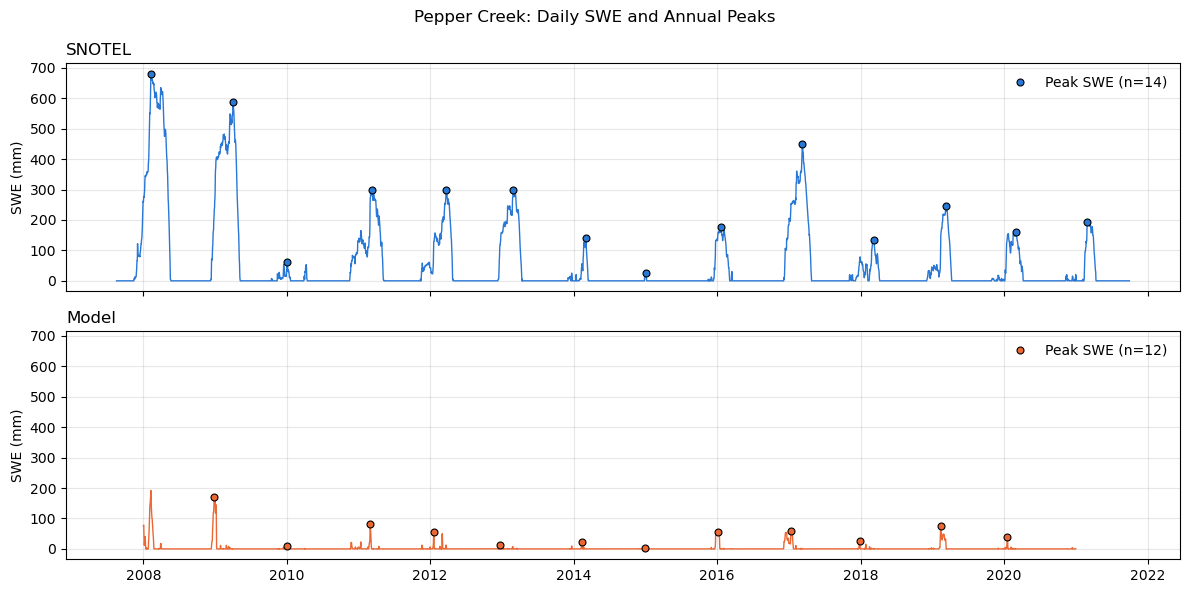

In [8]:
# Initial plot
# Daily SWE with the retained annual peaks marked, to check the peak selection and coverage filter
sources = {
    'snotel': (snotel_data['swe_mm'], 'SNOTEL', '#2a78d6'),
    'model': (model_swe['swe_mm'], 'Model', '#eb6834'),
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (col, (swe, label, color)) in zip(axes, sources.items()):
    valid = swe.dropna()
    water_year = np.where(valid.index.month >= 10, valid.index.year + 1, valid.index.year)
    peak_dates = valid.groupby(water_year).idxmax()
    peak_dates = peak_dates[peak_dates.index.isin(peak_swe[col].dropna().index)]

    ax.plot(swe.index, swe, color=color, lw=1)
    ax.plot(peak_dates, swe.loc[peak_dates], 'o', ms=5, color=color, mec='k', mew=0.8,
            label=f'Peak SWE (n={len(peak_dates)})')
    ax.set_title(label, loc='left')
    ax.set_ylabel('SWE (mm)')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', frameon=False)

fig.suptitle(f'{site}: Daily SWE and Annual Peaks')
fig.tight_layout()
plt.show()

### Calculate CDF from Peak SWE
- Xi is sorted peak SWE
- Fi is estimated probability
$$ F_i = i/(N+1) $$

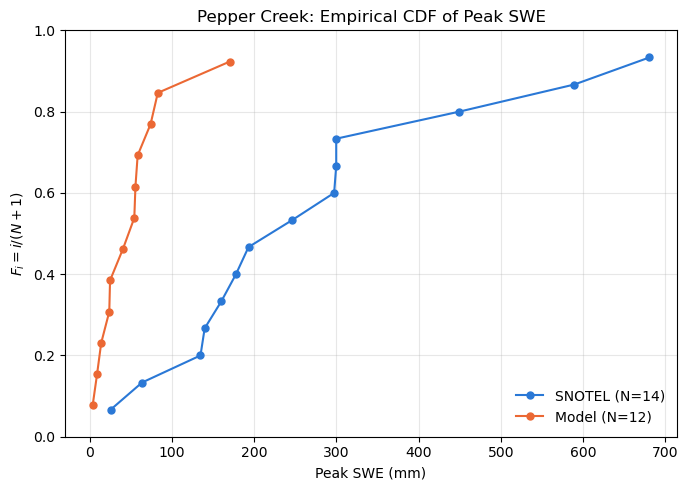

In [9]:
# Empirical CDF (Weibull plotting position), with N counted separately for each source
def empirical_cdf(values: pd.Series) -> pd.DataFrame:
    xi = np.sort(values.dropna().to_numpy())
    n = len(xi)
    fi = np.arange(1, n + 1) / (n + 1)
    return pd.DataFrame({'Xi': xi, 'Fi': fi}, index=pd.RangeIndex(1, n + 1, name='i'))


cdfs = {col: empirical_cdf(peak_swe[col]) for col in peak_swe.columns}

fig, ax = plt.subplots(figsize=(7, 5))
for col, label, color in [('snotel', 'SNOTEL', '#2a78d6'), ('model', 'Model', '#eb6834')]:
    cdf = cdfs[col]
    ax.plot(cdf['Xi'], cdf['Fi'], 'o-', color=color, lw=1.5, ms=5, label=f'{label} (N={len(cdf)})')

ax.set_xlabel('Peak SWE (mm)')
ax.set_ylabel('$F_i = i/(N+1)$')
ax.set_ylim(0, 1)
ax.set_title(f'{site}: Empirical CDF of Peak SWE')
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Return Period from CDF
- Ti is the return period (years) of a peak SWE exceeding Xi
$$ T_i = 1/(1-F_i) $$

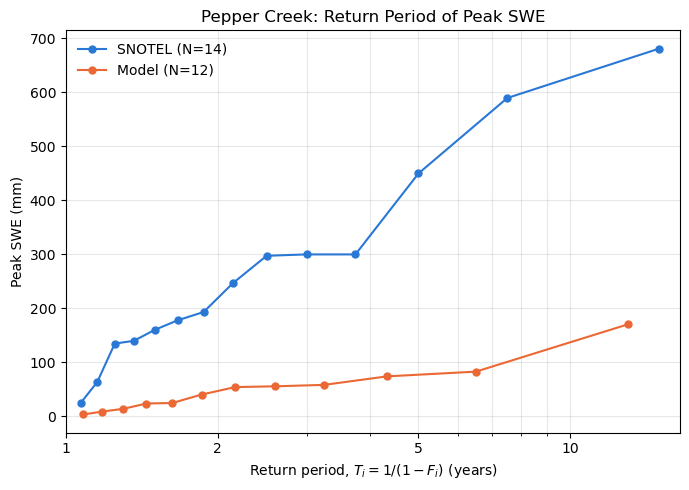

In [10]:
# Return period
for cdf in cdfs.values():
    cdf['Ti'] = 1 / (1 - cdf['Fi'])

fig, ax = plt.subplots(figsize=(7, 5))
for col, label, color in [('snotel', 'SNOTEL', '#2a78d6'), ('model', 'Model', '#eb6834')]:
    cdf = cdfs[col]
    ax.plot(cdf['Ti'], cdf['Xi'], 'o-', color=color, lw=1.5, ms=5, label=f'{label} (N={len(cdf)})')

max_ti = max(cdf['Ti'].max() for cdf in cdfs.values())
ax.set_xscale('log')
ax.set_xticks([t for t in [1, 2, 5, 10, 20, 50, 100] if t <= max_ti])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlim(1, max_ti * 1.1)
ax.set_xlabel('Return period, $T_i = 1/(1-F_i)$ (years)')
ax.set_ylabel('Peak SWE (mm)')
ax.set_title(f'{site}: Return Period of Peak SWE')
ax.grid(alpha=0.3, which='both')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

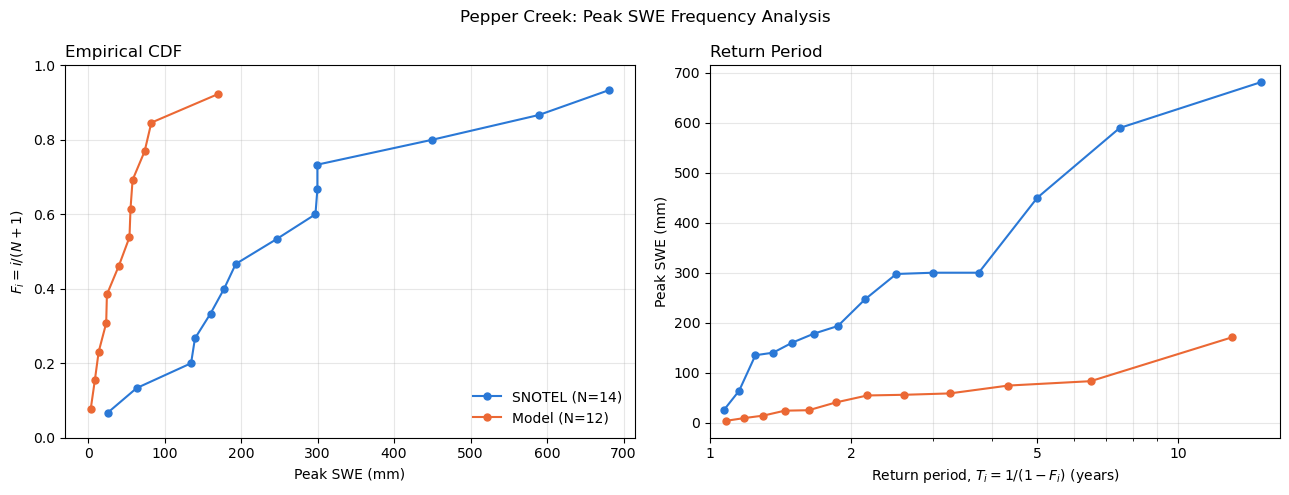

In [11]:
# Combined CDF and return period plot
fig, (ax_cdf, ax_ti) = plt.subplots(1, 2, figsize=(13, 5))
for col, label, color in [('snotel', 'SNOTEL', '#2a78d6'), ('model', 'Model', '#eb6834')]:
    cdf = cdfs[col]
    ax_cdf.plot(cdf['Xi'], cdf['Fi'], 'o-', color=color, lw=1.5, ms=5, label=f'{label} (N={len(cdf)})')
    ax_ti.plot(cdf['Ti'], cdf['Xi'], 'o-', color=color, lw=1.5, ms=5, label=f'{label} (N={len(cdf)})')

ax_cdf.set_xlabel('Peak SWE (mm)')
ax_cdf.set_ylabel('$F_i = i/(N+1)$')
ax_cdf.set_ylim(0, 1)
ax_cdf.set_title('Empirical CDF', loc='left')
ax_cdf.grid(alpha=0.3)
ax_cdf.legend(frameon=False)

max_ti = max(cdf['Ti'].max() for cdf in cdfs.values())
ax_ti.set_xscale('log')
ax_ti.set_xticks([t for t in [1, 2, 5, 10, 20, 50, 100] if t <= max_ti])
ax_ti.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax_ti.set_xlim(1, max_ti * 1.1)
ax_ti.set_xlabel('Return period, $T_i = 1/(1-F_i)$ (years)')
ax_ti.set_ylabel('Peak SWE (mm)')
ax_ti.set_title('Return Period', loc='left')
ax_ti.grid(alpha=0.3, which='both')

fig.suptitle(f'{site}: Peak SWE Frequency Analysis')
fig.tight_layout()
fig.savefig(f'../images/cdf_{site}.png', bbox_inches='tight')
plt.show()